In [1]:
import torch
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

iris = load_iris()
X = iris.data
y = iris.target


# Standardize the features
scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Convert data to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

In [73]:
class SelfAttention(nn.Module):
    def __init__(self, embed_dim):
        super(SelfAttention, self).__init__()
        self.embed_dim = embed_dim
        self.query = nn.Linear(embed_dim, embed_dim)
        self.key = nn.Linear(embed_dim, embed_dim)
        self.value = nn.Linear(embed_dim, embed_dim)
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        # Compute Q, K, V matrices
        Q = self.query(x)  # (batch_size, seq_len, embed_dim)
        K = self.key(x)    # (batch_size, seq_len, embed_dim)
        V = self.value(x)  # (batch_size, seq_len, embed_dim)

        # Compute attention scores
        scores = torch.bmm(Q, K.transpose(1, 2))  # (batch_size, seq_len, seq_len)
        scores = scores / (self.embed_dim ** 0.5)  # Scale by sqrt(embed_dim)

        # Apply softmax to get attention weights
        attention_weights = self.softmax(scores)  # (batch_size, seq_len, seq_len)

        # Compute weighted sum of values
        output = torch.bmm(attention_weights, V)  # (batch_size, seq_len, embed_dim)

        return output, attention_weights
    

In [74]:
class ClassificationModel(nn.Module):
    def __init__(self, embed_dim, num_classes):
        super(ClassificationModel, self).__init__()
        self.self_attention = SelfAttention(embed_dim)
        self.fc = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        # Apply self-attention layer
        attention_output, attention_weights = self.self_attention(x)  # (batch_size, seq_len, embed_dim)

        # Pooling: Take the mean across the sequence dimension
        pooled_output = attention_output.mean(dim=1)  # (batch_size, embed_dim)

        # Apply fully connected layer for classification
        predictions = self.fc(pooled_output)  # (batch_size, num_classes)

        return predictions, attention_weights

In [84]:

# Initialize the model, loss function, and optimizer
input_dim = X_train.shape[1]
num_classes = len(set(y))
model = AttentionClassifier(input_dim, num_classes)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train the model
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    predictions, _ = model(X_train.unsqueeze(1))
    loss = criterion(predictions, y_train)
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {loss.item():.4f}')

# Evaluate the model
model.eval()
with torch.no_grad():
    test_predictions, test_attention_weights = model(X_test.unsqueeze(1))
    test_predictions = test_predictions.argmax(dim=1).numpy()
    accuracy = accuracy_score(y_test, test_predictions)
    print(f'Test Accuracy: {accuracy:.4f}')

Epoch [10/100], Loss: 0.8908
Epoch [20/100], Loss: 0.8579
Epoch [30/100], Loss: 0.8266
Epoch [40/100], Loss: 0.7968
Epoch [50/100], Loss: 0.7684
Epoch [60/100], Loss: 0.7414
Epoch [70/100], Loss: 0.7157
Epoch [80/100], Loss: 0.6914
Epoch [90/100], Loss: 0.6684
Epoch [100/100], Loss: 0.6467
Test Accuracy: 0.9333


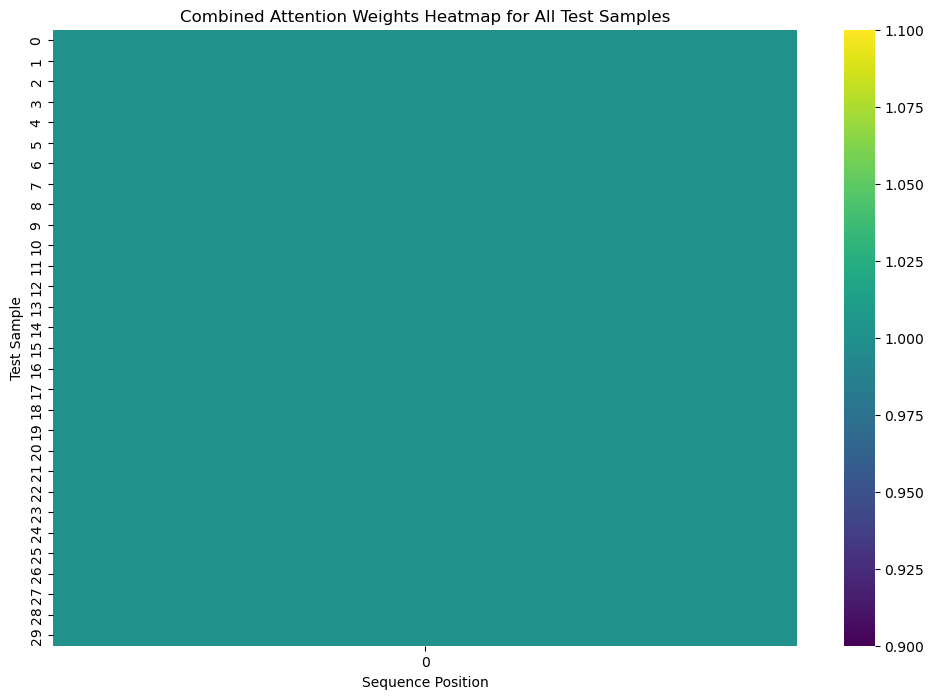

In [87]:
# Combine attention weights for all test samples into one large matrix
all_attention_weights = []
for i in range(len(X_test)):
    attention_weights_example = test_attention_weights[i].cpu().numpy()  # Get attention weights for the i-th test sample
    all_attention_weights.append(attention_weights_example)

# Convert the list of attention weights into a numpy array
all_attention_weights = np.array(all_attention_weights)


plt.figure(figsize=(12, 8))
sns.heatmap(all_attention_weights.mean(axis=2), cmap='viridis', cbar=True)  # Averaging over attention heads 
plt.title('Combined Attention Weights Heatmap for All Test Samples')
plt.xlabel('Sequence Position')
plt.ylabel('Test Sample')
plt.show()


In [31]:
import math

# 1. Data Preprocessing
with open("Harry_Potter_all_books_preprocessed.txt", "r", encoding="utf-8") as f:
    text = f.read().lower()

# Tokenize and restrict to 50,000 tokens
tokens = text.split()[:50000]
vocab = set(tokens)
vocab_size = len(vocab)

# Create vocabulary mapping
word_to_idx = {word: idx for idx, word in enumerate(vocab)}
idx_to_word = {idx: word for word, idx in word_to_idx.items()}

# 2. Language Model Dataset
class LanguageModelDataset(torch.utils.data.Dataset):
    def __init__(self, tokens, seq_len=50):
        self.seq_len = seq_len
        self.tokens = tokens
        self.data = [self.tokens[i:i + seq_len] for i in range(len(self.tokens) - seq_len)]
    
    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sequence = self.data[idx]
        input_seq = sequence[:-1]
        target_seq = sequence[1:]
        input_tensor = torch.tensor([word_to_idx[word] for word in input_seq], dtype=torch.long)
        target_tensor = torch.tensor([word_to_idx[word] for word in target_seq], dtype=torch.long)
        return input_tensor, target_tensor

# Positional Encoding
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)  # Add batch dimension
        self.register_buffer('pe', pe)

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

# Multi-Head Self-Attention
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super(MultiHeadAttention, self).__init__()
        assert d_model % num_heads == 0
        self.d_k = d_model // num_heads
        self.num_heads = num_heads

        self.qkv_proj = nn.Linear(d_model, d_model * 3)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x, mask=None):
        batch_size, seq_len, d_model = x.size()
        qkv = self.qkv_proj(x).view(batch_size, seq_len, 3, self.num_heads, self.d_k)
        q, k, v = qkv.unbind(dim=2)  # Split into q, k, v tensors
        q, k, v = [t.permute(0, 2, 1, 3) for t in (q, k, v)]  # Rearrange to (batch, head, seq, d_k)

        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_k)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))
        attn = F.softmax(scores, dim=-1)

        context = torch.matmul(attn, v).permute(0, 2, 1, 3).contiguous()
        context = context.view(batch_size, seq_len, d_model)
        return self.out_proj(context)

# Feed-Forward Layer
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff):
        super(FeedForward, self).__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)

    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))

# Transformer Block
class TransformerBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super(TransformerBlock, self).__init__()
        self.attention = MultiHeadAttention(d_model, num_heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff = FeedForward(d_model, d_ff)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        # Multi-head attention
        attn_out = self.attention(x, mask)
        x = self.norm1(x + self.dropout(attn_out))

        # Feed-forward
        ff_out = self.ff(x)
        x = self.norm2(x + self.dropout(ff_out))
        return x

# Transformer Model
class TransformerTextGenerator(nn.Module):
    def __init__(self, vocab_size, d_model, num_heads, d_ff, num_layers, max_len, dropout=0.1):
        super(TransformerTextGenerator, self).__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.positional_encoding = PositionalEncoding(d_model, max_len)
        self.layers = nn.ModuleList([
            TransformerBlock(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)
        ])
        self.fc_out = nn.Linear(d_model, vocab_size)

    def generate_mask(self, seq_len):
        mask = torch.triu(torch.ones(seq_len, seq_len), diagonal=1)
        return mask == 0  # Invert mask for causal attention

    def forward(self, x):
        batch_size, seq_len = x.size()
        mask = self.generate_mask(seq_len).to(x.device)

        x = self.embedding(x) * math.sqrt(x.size(-1))
        x = self.positional_encoding(x)

        for layer in self.layers:
            x = layer(x, mask)

        logits = self.fc_out(x)
        return logits

# Training Loop Setup

# Hyperparameters
VOCAB_SIZE = len(vocab)  # Vocabulary size from preprocessed text
D_MODEL = 512
NUM_HEADS = 8
D_FF = 2048
NUM_LAYERS = 6
MAX_LEN = 50  # Max sequence length for each input
DROPOUT = 0.1
BATCH_SIZE = 16
EPOCHS = 5
LEARNING_RATE = 1e-4

# Instantiate the model
model = TransformerTextGenerator(VOCAB_SIZE, D_MODEL, NUM_HEADS, D_FF, NUM_LAYERS, MAX_LEN, DROPOUT)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss()

# Prepare the dataset and dataloader
dataset = LanguageModelDataset(tokens, seq_len=MAX_LEN)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)


# Training Loop
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for batch_idx, (input_tensor, target_tensor) in enumerate(dataloader):
        optimizer.zero_grad()

        # Forward pass
        output = model(input_tensor)

        # Flatten the output and target tensor to match for loss calculation
        output = output.view(-1, VOCAB_SIZE)
        target_tensor = target_tensor.view(-1)

        # Compute the loss
        loss = criterion(output, target_tensor)
        total_loss += loss.item()

        # Backward pass
        loss.backward()
        optimizer.step()

        target_loss = 0.3 
    
        # Print every 500 batches 
        if batch_idx % 500 == 0:
            print(f"Epoch [{epoch + 1}/{EPOCHS}], Batch [{batch_idx}/{len(dataloader)}], Loss: {loss.item():.4f}")
        
        # Early stopping based on the loss threshold
        if loss.item() < target_loss:
            print(f"Stopping early at epoch {epoch} due to loss threshold.")
            break

    # Print only the average loss at the end of each epoch
    print(f"Epoch [{epoch + 1}/{EPOCHS}], Average Loss: {total_loss / len(dataloader):.4f}")


Epoch [1/5], Batch [0/3122], Loss: 8.7782
Epoch [1/5], Batch [500/3122], Loss: 4.9090
Epoch [1/5], Batch [1000/3122], Loss: 3.4800
Epoch [1/5], Batch [1500/3122], Loss: 2.2244
Epoch [1/5], Batch [2000/3122], Loss: 1.2585
Epoch [1/5], Batch [2500/3122], Loss: 0.7819
Epoch [1/5], Batch [3000/3122], Loss: 0.5087
Epoch [1/5], Average Loss: 2.6575
Epoch [2/5], Batch [0/3122], Loss: 0.4495
Epoch [2/5], Batch [500/3122], Loss: 0.4190
Stopping early at epoch 1 due to loss threshold.
Epoch [2/5], Average Loss: 0.0848
Epoch [3/5], Batch [0/3122], Loss: 0.3626
Stopping early at epoch 2 due to loss threshold.
Epoch [3/5], Average Loss: 0.0012
Epoch [4/5], Batch [0/3122], Loss: 0.3416
Stopping early at epoch 3 due to loss threshold.
Epoch [4/5], Average Loss: 0.0012
Epoch [5/5], Batch [0/3122], Loss: 0.2880
Stopping early at epoch 4 due to loss threshold.
Epoch [5/5], Average Loss: 0.0001


In [36]:
def generate_text(prompt, max_length=50):
    model.eval()  # Set the model to evaluation mode
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)  # Move model to the appropriate device

    # Check if the word_to_idx dictionary contains "<UNK>", and add it if missing
    if "<UNK>" not in word_to_idx:
        word_to_idx["<UNK>"] = len(word_to_idx)  # Assign a new index for "<UNK>"
        idx_to_word[len(idx_to_word)] = "<UNK>"  # Update the idx_to_word dictionary

    # Convert the initial prompt to its corresponding index in the vocabulary
    generated_tokens = [word_to_idx.get(prompt, word_to_idx["<UNK>"])]  # Handle unknown words

    for _ in range(max_length - 1):
        input_tensor = torch.tensor([generated_tokens], dtype=torch.long).to(device)  # Convert list to tensor
        with torch.no_grad():
            # Get the model's predictions for the next token
            outputs = model(input_tensor)
            next_token_logits = outputs[0, -1, :]  # Get the logits for the last token
            next_token = torch.argmax(next_token_logits).item()  # Get the predicted token's index
            generated_tokens.append(next_token)  # Add the predicted token to the sequence

            # Stop if the model generates an <EOS> token
            if idx_to_word[next_token] == "<EOS>":
                break

    # Convert token indices back to words to form the generated text
    generated_text = " ".join(idx_to_word[token] for token in generated_tokens)
    return generated_text


In [37]:
test_prompt = "from"
generated_text = generate_text(test_prompt, max_length=50)

print(f"Prompt: {test_prompt}")
print(f"Generated Text: {generated_text}")

Prompt: from
Generated Text: from the ceiling and floor .that does it said hagrid importantly throwing out his hand tears in the way ?came malfoys sneering face .they had gone mad eyes .whats the matter ?in a low whisper harry looked like a wounded dog that filled ron .and what are you doing checking


In [40]:
test_prompt = "said"
generated_text = generate_text(test_prompt, max_length=50)

print(f"Prompt: {test_prompt}")
print(f"Generated Text: {generated_text}")

Prompt: said
Generated Text: said hagrid .tell yeh great muggle world everyone else is .you what ?hagrid looked shocked .listen here ive told yeh drop it .its nothin to you what that dogs guardin .we just want to know who nicolas flamel is thats all said hermione .unless youd like to tell us and


In [41]:
test_prompt = "need"
generated_text = generate_text(test_prompt, max_length=50)

print(f"Prompt: {test_prompt}")
print(f"Generated Text: {generated_text}")

Prompt: need
Generated Text: need .harry turned out of his hand over and saw the window all three of them were sitting in the middle of the stands .why would do is he told them in the house wandering around the school separately .harrys broom tightly with both of the crowd while the window
